# BRFSS Prevalence Data: General Exploration (v1.1)

A first look at `data/BRFSS_Prevalence_Data.csv`.

This notebook expects to sit in the folder that contains the `data` folder.

**Changes from v1.0**

- Only 13 of the 27 columns are loaded (the list and reasons are in Section 2)
- Numbers written with commas, such as `1,025` in `Sample_Size`, are now read as numbers instead of text
- The 2011 filter is replaced by a check, since the file already starts in 2011

**Sections**

1. Setup
2. Load the file
3. Year check
4. First look at rows
5. Columns and types
6. Categorical columns
7. Numeric columns
8. Rows per year
9. Duplicate check
10. Quick plots

## 1. Setup

Imports and display settings. By default pandas hides middle columns and long text with `...`.
The options below make pandas show every column and more of each text value.

In [1]:
import time
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# show every column instead of collapsing the middle ones into "..."
pd.set_option("display.max_columns", None)
# allow wide tables to stretch across the screen
pd.set_option("display.width", 200)
# show up to 80 characters of each text cell before cutting it off
pd.set_option("display.max_colwidth", 80)

print("pandas version:", pd.__version__)

pandas version: 3.0.5


## 2. Load the file

**Columns kept**

| Column | What it holds |
|---|---|
| Year | Survey year |
| Locationabbr, Locationdesc | State or territory code and name (includes a "US" median row) |
| Class, Topic, Question | Broad category, narrower topic, and survey question |
| Response | The answer category the row describes, for example "Yes" or "Retired" |
| Break_Out_Category, Break_Out | Grouping type (Sex, Age Group, and so on) and the group itself (Female, 25-34, and so on) |
| Sample_Size | Number of people surveyed in that group |
| Data_value | Percent of the group giving that response |
| Confidence_limit_Low, Confidence_limit_High | 95% confidence limits for Data_value |

**Columns dropped**

- `Data_value_unit`, `Data_value_type`, `DataSource`: the same value in every row
- `Display_order`: sort order for the CDC website only
- `Data_Value_Footnote`, `Data_Value_Footnote_Symbol`: reasons a Data_value is missing
- `ClassId`, `TopicId`, `LocationID`, `BreakoutID`, `BreakOutCategoryID`, `QuestionID`, `ResponseID`: ID codes for the text columns
- `GeoLocation`: latitude and longitude, not needed when states are identified by code

**Read options**

- `usecols` reads only the listed columns, which cuts load time and memory
- `thousands=","` removes the commas in numbers such as `1,025` so the column is read as numbers.
  Text such as `$50,000+` stays text because it is not a number even without the comma
- `low_memory=False` reads the whole file before deciding each column's type, which avoids a "mixed types" warning

In [2]:
data_path = Path("data") / "BRFSS_Prevalence_Data.csv"

# stop with a clear message if the file is not where expected
if not data_path.exists():
    raise FileNotFoundError(
        f"File not found at {data_path.resolve()}. "
        "Check that the notebook sits in the folder that contains the data folder."
    )

# st_size is the size in bytes, divided by 1024 twice to get megabytes
file_mb = data_path.stat().st_size / 1024**2
print(f"File size on disk: {file_mb:,.1f} MB")

File size on disk: 1,174.8 MB


In [3]:
keep_cols = [
    "Year",
    "Locationabbr",
    "Locationdesc",
    "Class",
    "Topic",
    "Question",
    "Response",
    "Break_Out_Category",
    "Break_Out",
    "Sample_Size",
    "Data_value",
    "Confidence_limit_Low",
    "Confidence_limit_High",
]

start = time.perf_counter()
df = pd.read_csv(data_path, usecols=keep_cols, thousands=",", low_memory=False)
elapsed = time.perf_counter() - start

# usecols keeps the file's column order, selecting by the list puts the columns in the order of keep_cols
df = df[keep_cols]

# deep=True measures the real size of text columns, not just the pointers to them
df_mb = df.memory_usage(deep=True).sum() / 1024**2

print(f"Loaded in {elapsed:,.1f} seconds")
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
print(f"Memory used in Python: {df_mb:,.1f} MB")

Loaded in 19.9 seconds
Rows: 3,211,643   Columns: 13
Memory used in Python: 1,785.4 MB


## 3. Year check

The v1.0 run showed the file already starts in 2011. Years before 2011 are not comparable with later
years because BRFSS changed its weighting method and added cell phone samples that year.

Instead of filtering, the cell below stops with an error if a future export ever contains years before 2011.

In [4]:
print("Year range:", df["Year"].min(), "to", df["Year"].max())

# assert raises an error with the message after the comma when the condition is False
assert df["Year"].min() >= 2011, "File contains years before 2011, filter before continuing"

Year range: 2011 to 2025


## 4. First look at rows

`head()` shows the first rows, `tail()` the last rows, and `sample()` a random set of rows.
The file is sorted, so the random sample gives a fairer picture than the top and bottom alone.
`random_state=1` makes the same random rows appear each time the cell runs.

In [5]:
df.head()

,Year,Locationabbr,Locationdesc,Class,Topic,Question,Response,Break_Out_Category,Break_Out,Sample_Size,Data_value,Confidence_limit_Low,Confidence_limit_High
0,2025,AK,Alaska,Chronic Health Indicators,Depression,Ever told you that you have a form of depression?,Yes,Overall,Overall,1025,22.0,20.2,23.7
1,2025,AK,Alaska,Chronic Health Indicators,Depression,Ever told you that you have a form of depression?,No,Overall,Overall,4474,78.0,76.3,79.8
2,2025,AK,Alaska,Chronic Health Indicators,Depression,Ever told you that you have a form of depression?,Yes,Sex,Male,370,15.6,13.6,17.5
3,2025,AK,Alaska,Chronic Health Indicators,Depression,Ever told you that you have a form of depression?,No,Sex,Male,2436,84.5,82.5,86.4
4,2025,AK,Alaska,Chronic Health Indicators,Depression,Ever told you that you have a form of depression?,Yes,Sex,Female,655,29.1,26.3,31.9


In [6]:
df.tail()

,Year,Locationabbr,Locationdesc,Class,Topic,Question,Response,Break_Out_Category,Break_Out,Sample_Size,Data_value,Confidence_limit_Low,Confidence_limit_High
3211638,2011,WY,Wyoming,Demographics,Employment,What is your employment status?,No work >yr,Household Income,"$50,000+",12,NaN,NaN,NaN
3211639,2011,WY,Wyoming,Demographics,Employment,What is your employment status?,Homemkr,Household Income,"$50,000+",224,7.9,6.5,9.3
3211640,2011,WY,Wyoming,Demographics,Employment,What is your employment status?,Student,Household Income,"$50,000+",33,4.1,2.6,5.7
3211641,2011,WY,Wyoming,Demographics,Employment,What is your employment status?,Retired,Household Income,"$50,000+",436,7.9,6.8,9.0
3211642,2011,WY,Wyoming,Demographics,Employment,What is your employment status?,Unable to work,Household Income,"$50,000+",22,NaN,NaN,NaN


In [7]:
df.sample(10, random_state=1)

,Year,Locationabbr,Locationdesc,Class,Topic,Question,Response,Break_Out_Category,Break_Out,Sample_Size,Data_value,Confidence_limit_Low,Confidence_limit_High
1275262,2020,MS,Mississippi,Chronic Health Indicators,COPD,Ever told you have COPD?,Yes,Household Income,"$35,000-$49,999",46,4.8,3.1,6.6
1860235,2017,DC,District of Columbia,Injury,Seatbelt Use,Always or nearly always wears a seat belt?,No,Race/Ethnicity,"American Indian or Alaskan Native, non-Hispanic",0,NaN,NaN,NaN
1987257,2017,OH,Ohio,E-Cigarette Use,E-Cigarette Use,E-cigarette use status,Current E-cigarette user - some days,Age Group,65+,34,NaN,NaN,NaN
2860364,2013,OR,Oregon,Alcohol Consumption,Alcohol Consumption,Adults who have had at least one drink of alcohol within the past 30 days,Yes,Age Group,25-34,415,70.0,65.6,74.5
3045189,2012,TX,Texas,Demographics,Education,What is the highest grade or year of school you completed?,Less than H.S.,Household Income,"$15,000-$24,999",387,34.6,31.1,38.2
1401673,2019,CA,California,Chronic Health Indicators,Arthritis,Are you now limited in any way in any of your usual activities because of ar...,"Have arthritis, have limited usual activities",Race/Ethnicity,"Asian, non-Hispanic",36,4.4,2.7,6.1
2010242,2017,RI,Rhode Island,Chronic Health Indicators,Skin Cancer,Ever told you had skin cancer?,No,Race/Ethnicity,"Other, non-Hispanic",89,87.5,77.8,97.1
512634,2023,ID,Idaho,Demographics,Employment,What is your employment status?,Unable to work,Education Attained,H.S. or G.E.D.,123,5.2,4.0,6.4
2255686,2016,US,"All States, DC and Territories (median) **",Demographics,Race,What is your race/ethnicity?,Hispanic,Overall,Overall,54,8.2,NaN,NaN
775492,2022,MD,Maryland,Chronic Health Indicators,Diabetes,Have you ever been told by a doctor that you have diabetes?,Yes,Education Attained,College graduate,888,8.8,7.9,9.7


## 5. Columns and types

One row per column of the data: its type, how many values are filled in, how many are missing,
and how many different values it holds.

`Sample_Size` should now show a numeric type (`int64` or `float64`) instead of text.

In [8]:
n_rows = len(df)

col_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_missing": df.notna().sum(),
    "missing": df.isna().sum(),
})
col_summary["pct_missing"] = (col_summary["missing"] / n_rows * 100).round(1)
# nunique counts distinct values and skips missing ones
col_summary["n_unique"] = df.nunique()

col_summary

,dtype,non_missing,missing,pct_missing,n_unique
Year,int64,3211643,0,0.0,15
Locationabbr,str,3211643,0,0.0,56
Locationdesc,str,3211643,0,0.0,56
Class,str,3211643,0,0.0,21
Topic,str,3211643,0,0.0,66
Question,str,3211643,0,0.0,101
Response,str,3191134,20509,0.6,153
Break_Out_Category,str,3211643,0,0.0,6
Break_Out,str,3211643,0,0.0,49
Sample_Size,int64,3211643,0,0.0,15371


## 6. Categorical columns

Each column below gets its own table listing every value, how many rows have it, and the percent of all rows.
Missing values appear as their own row (NaN).

In [17]:
from IPython.display import display


def show_counts(col_name):
    """
    Display every value of one column with its count and percent of rows

    Parameters
    ----------
    col_name : str
        Name of the column in df to summarize
    """
    # dropna=False keeps missing values as their own row instead of skipping them
    counts = df[col_name].value_counts(dropna=False)
    # reset_index turns the values from the index into a regular column next to the counts
    table = counts.rename_axis(col_name).reset_index(name="count")
    table["percent"] = (table["count"] / len(df) * 100).round(2)
    print(f"{col_name}: {df[col_name].nunique():,} distinct values, {df[col_name].isna().sum():,} missing")
    # option_context lifts the row limit only inside this block, so long tables show every row
    with pd.option_context("display.max_rows", None):
        display(table)

### Locationabbr

In [19]:
show_counts("Locationabbr")

Locationabbr: 56 distinct values, 0 missing


,Locationabbr,count,percent
0,NE,60793,1.89
1,SC,60791,1.89
2,MA,60790,1.89
3,KS,60789,1.89
4,OK,60788,1.89
5,MN,60787,1.89
6,MI,60786,1.89
7,OH,60786,1.89
8,NC,60784,1.89
9,TX,60784,1.89


In [20]:
show_counts("Locationdesc")
show_counts("Class")
show_counts("Topic")
show_counts("Question")
show_counts("Response")
show_counts("Break_Out_Category")
show_counts("Break_Out")

Locationdesc: 56 distinct values, 0 missing


,Locationdesc,count,percent
0,Nebraska,60793,1.89
1,South Carolina,60791,1.89
2,Massachusetts,60790,1.89
3,Kansas,60789,1.89
4,Oklahoma,60788,1.89
5,Minnesota,60787,1.89
6,Michigan,60786,1.89
7,Ohio,60786,1.89
8,North Carolina,60784,1.89
9,Texas,60784,1.89


Class: 21 distinct values, 0 missing


,Class,count,percent
0,Demographics,1130546,35.20
1,Chronic Health Indicators,624936,19.46
2,Health Care Access/Coverage,261040,8.13
3,Tobacco Use,177162,5.52
4,Health Status,143534,4.47
5,Alcohol Consumption,123041,3.83
6,Physical Activity,89100,2.77
7,Immunization,84187,2.62
8,Overweight and Obesity (BMI),81978,2.55
9,Cholesterol Awareness,62154,1.94


Topic: 66 distinct values, 0 missing


,Topic,count,percent
0,Disability status,205698,6.40
1,Employment,163820,5.10
2,Cardiovascular Disease,151380,4.71
3,Marital Status,122917,3.83
4,Number of Children,122806,3.82
5,Race,106941,3.33
6,Overall Health,102517,3.19
7,Arthritis,97867,3.05
8,Age,94517,2.94
9,Income,91136,2.84


... (4 outputs left out)

Break_Out_Category: 6 distinct values, 0 missing


,Break_Out_Category,count,percent
0,Race/Ethnicity,896236,27.91
1,Age Group,713813,22.23
2,Household Income,707308,22.02
3,Education Attained,504716,15.72
4,Sex,255315,7.95
5,Overall,134255,4.18


Break_Out: 49 distinct values, 0 missing


,Break_Out,count,percent
0,Overall,134255,4.18
1,Female,128080,3.99
2,Male,127235,3.96
3,College graduate,126185,3.93
4,H.S. or G.E.D.,126183,3.93
5,Some post-H.S.,126181,3.93
6,Less than H.S.,126167,3.93
7,"$15,000-$24,999",124864,3.89
8,"Less than $15,000",124860,3.89
9,"$25,000-$34,999",124847,3.89


In [9]:
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print(f"{len(cat_cols)} non-numeric columns:")
print(cat_cols)

8 non-numeric columns:
['Locationabbr', 'Locationdesc', 'Class', 'Topic', 'Question', 'Response', 'Break_Out_Category', 'Break_Out']


In [10]:
full_limit = 60
top_n = 15

for col in cat_cols:
    n_unique = df[col].nunique()
    print(f"\n{col}  ({n_unique:,} distinct values)")
    # dropna=False also counts missing values as their own row in the output
    counts = df[col].value_counts(dropna=False)
    if n_unique <= full_limit:
        print(counts.to_string())
    else:
        print(f"Top {top_n} only:")
        print(counts.head(top_n).to_string())


Locationabbr  (56 distinct values)
Locationabbr
NE    60793
SC    60791
MA    60790
KS    60789
OK    60788
MN    60787
MI    60786
OH    60786
NC    60784
TX    60784
UT    60783
LA    60781
CO    60779
GA    60778
VA    60778
HI    60777
IN    60777
MO    60774
AL    60771
NM    60771
NY    60768
IA    60765
AK    60760
IL    60760
WI    60759
DE    60757
SD    60757
OR    60753
WY    60746
ME    60744
WV    60742
MT    60741
MD    60735
WA    60734
AZ    60732
DC    60730
AR    60716
ID    60714
CT    60709
RI    60703
GU    60691
ND    60691
NH    60690
VT    60666
PR    60285
NJ    56502
CA    56491
NV    56473
MS    56438
TN    56359
KY    56316
PA    56316
FL    56236
VI    22117
US     2450
UW     2450

Locationdesc  (56 distinct values)
Locationdesc
Nebraska                                      60793
South Carolina                                60791
Massachusetts                                 60790
Kansas                                        60789
Oklahoma              

## 7. Numeric columns

`describe()` gives count, mean, standard deviation, minimum, quartiles, and maximum for every
numeric column. `.T` flips the table so each column of the data becomes a row, which is easier to read.

The mean of `Year` only describes how rows are spread over years, not anything about health.

## 8. Rows per year

In [12]:
# sort_index puts the years in order instead of by count
rows_per_year = df["Year"].value_counts().sort_index()
print(rows_per_year.to_string())

Year
2011    145364
2012    148824
2013    202751
2014    194798
2015    230101
2016    229714
2017    235303
2018    217579
2019    223058
2020    220975
2021    241435
2022    240688
2023    232512
2024    233371
2025    215170


## 9. Duplicate check

`duplicated()` marks a row as `True` when an identical earlier row exists (every column equal).
The count is reported only, no rows are removed.

v1.0 found no repeated rows across all 27 columns. With fewer columns, rows that differed only in a
dropped column (such as an ID code) can now look identical, so the count may change.

In [13]:
n_dup = int(df.duplicated().sum())
print(f"Fully repeated rows: {n_dup:,}")

# show a few repeated rows if any exist, keep=False marks every copy so both versions appear
if n_dup > 0:
    display(df[df.duplicated(keep=False)].head(10))

Fully repeated rows: 0


## 10. Quick plots

1. Rows per year
2. Distribution of `Data_value`
3. Rows per topic for the 20 most common topics

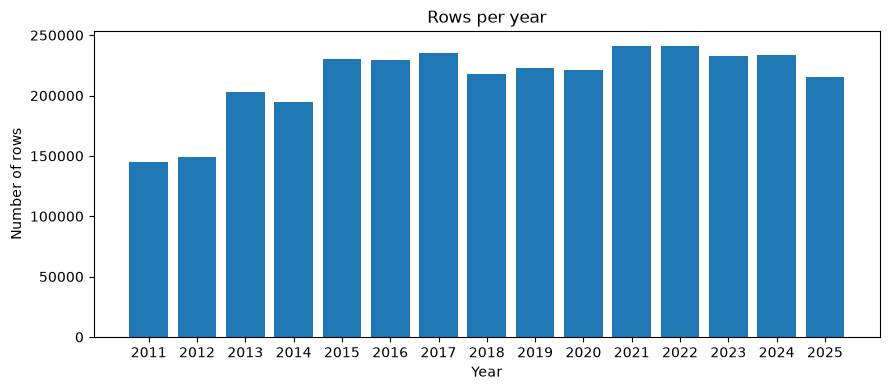

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(rows_per_year.index.astype(str), rows_per_year.values)
ax.set_title("Rows per year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of rows")
plt.tight_layout()
plt.show()

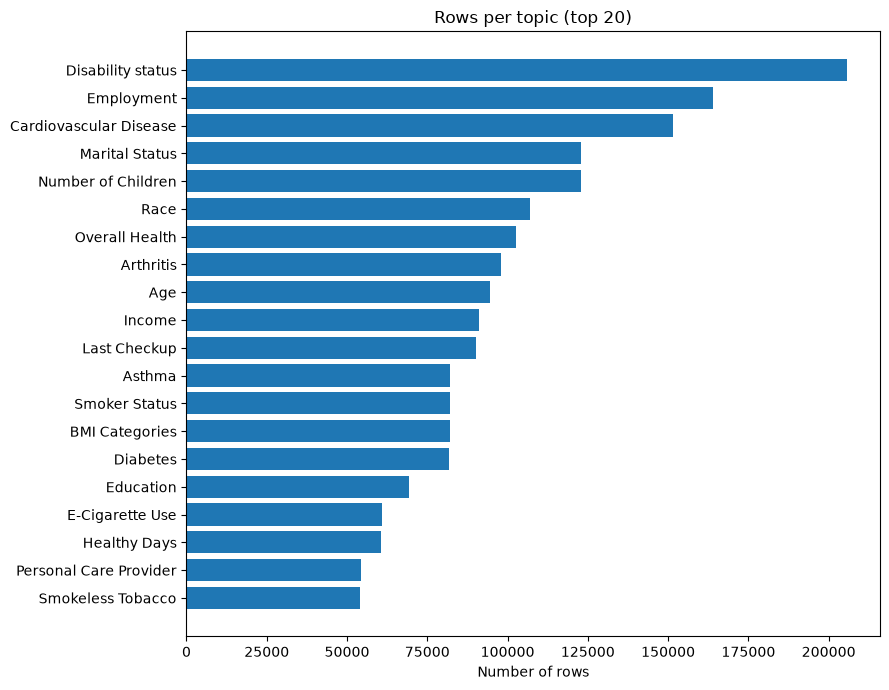

In [16]:
# sort_values flips the order so the largest bar appears at the top of the chart
top_topics = df["Topic"].value_counts().head(20).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_topics.index, top_topics.values)
ax.set_title("Rows per topic (top 20)")
ax.set_xlabel("Number of rows")
plt.tight_layout()
plt.show()